In [3]:
# Bank Marketing Dataset: Exploratory Data Analysis (EDA)
# Student Name:** Korra Akhil
# Email ID:** 2026mcb1536@iitrpr.ac.in
# Dataset:** UCI Bank Marketing Dataset (`bank-additional-full.csv` — 41,188 records, 21 attributes)


In [4]:
#section A
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Global styling & automatic chart export setup
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

if os.path.isfile('../outputs/graphs'):
    os.remove('../outputs/graphs')
os.makedirs('../outputs/graphs', exist_ok=True)

_orig_show = plt.show
_fig_count = 1
def _auto_save_show(*args, **kwargs):
    """Automatically save every plotted figure at 300 DPI before rendering."""
    global _fig_count
    plt.savefig(f'../outputs/graphs/chart_{_fig_count:02d}.png', dpi=300, bbox_inches='tight')
    _fig_count += 1
    _orig_show(*args, **kwargs)
plt.show = _auto_save_show

def run_section_a(filepath='../data/bank-additional-full.csv'):
    """
    Section A (Q1-Q6): Load dataset, inspect schema/memory, evaluate cardinality,
    missing values, 'unknown' categories, duplicates, and numerical summaries.
    """
    print("=" * 70)
    print("SECTION A: DATA LOADING, INSPECTION & PREPROCESSING (Q1 - Q6)")
    print("=" * 70)

    # Q01: Load dataset (UCI uses semicolon ';' delimiter)
    df = pd.read_csv(filepath, sep=';')
    print("\nQ01 - First 10 records:")
    display(df.head(10))
    print("Q01 - Last 10 records:")
    display(df.tail(10))

    # Q02: Shape, memory usage, data types, and variable categorization
    mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
    binary_cols = [c for c in df.columns if df[c].nunique() == 2]
    print(f"\nQ02 - Shape: {df.shape[0]:,} rows x {df.shape[1]} columns | Memory: {mem_mb:.2f} MB")
    print(f"Numerical features ({len(num_cols)}): {num_cols}")
    print(f"Categorical features ({len(cat_cols)}): {cat_cols}")
    print(f"Binary features ({len(binary_cols)}): {binary_cols}")

    # Q03: Unique values per column & highest cardinality categorical features
    nunique_series = df.nunique().sort_values(ascending=False)
    print("\nQ03 - Unique values per column:")
    print(nunique_series)
    cat_card = df[cat_cols].nunique().sort_values(ascending=False)
    print(f"Highest cardinality categorical features:\n{cat_card.head(3)}")

    # Q04: Standard null/missing values check
    null_counts = df.isnull().sum()
    null_pct = (null_counts / len(df)) * 100
    print("\nQ04 - Standard NaN Missing Values (Count & %):")
    print(pd.DataFrame({'Missing_Count': null_counts, 'Missing_Pct': null_pct}))

    # Q05: Investigate 'unknown' string values across categorical features
    print("\nQ05 - 'unknown' Category Analysis:")
    unknown_summary = {}
    for col in cat_cols:
        cnt = (df[col] == 'unknown').sum()
        if cnt > 0:
            unknown_summary[col] = {'Count': cnt, 'Percentage': round((cnt / len(df)) * 100, 2)}
    unknown_df = pd.DataFrame(unknown_summary).T.sort_values(by='Count', ascending=False)
    display(unknown_df)
    print("Decision: Keep 'unknown' as a distinct category rather than dropping/imputing, "
          "because non-disclosure (e.g., default='unknown' at 20.87%) carries behavioral signal.")

    # Q06: Duplicate records & numerical summary statistics
    dup_count = df.duplicated().sum()
    print(f"\nQ06 - Exact duplicate rows found: {dup_count}")
    print("Numerical Descriptive Statistics:")
    display(df.describe().T)
    print("Note: pdays=999 indicates client was never previously contacted (~96.3% of records).")

    return df

df = run_section_a()

SECTION A: DATA LOADING, INSPECTION & PREPROCESSING (Q1 - Q6)

Q01 - First 10 records:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Q01 - Last 10 records:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41178,62,retired,married,university.degree,no,no,no,cellular,nov,thu,...,2,6,3,success,-1.1,94.767,-50.8,1.031,4963.6,yes
41179,64,retired,divorced,professional.course,no,yes,no,cellular,nov,fri,...,3,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41180,36,admin.,married,university.degree,no,no,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41181,37,admin.,married,university.degree,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41182,29,unemployed,single,basic.4y,no,yes,no,cellular,nov,fri,...,1,9,1,success,-1.1,94.767,-50.8,1.028,4963.6,no
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no



Q02 - Shape: 41,188 rows x 21 columns | Memory: 26.80 MB
Numerical features (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features (11): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']
Binary features (2): ['contact', 'y']

Q03 - Unique values per column:
duration          1544
euribor3m          316
age                 78
campaign            42
pdays               27
cons.conf.idx       26
cons.price.idx      26
job                 12
nr.employed         11
month               10
emp.var.rate        10
previous             8
education            8
day_of_week          5
marital              4
default              3
poutcome             3
loan                 3
housing              3
contact              2
y                    2
dtype: int64
Highest cardinality categorical features:
job          12
month        10
edu

,Count,Percentage
default,8597.0,20.87
education,1731.0,4.20
housing,990.0,2.40
loan,990.0,2.40
job,330.0,0.80
marital,80.0,0.19


Decision: Keep 'unknown' as a distinct category rather than dropping/imputing, because non-disclosure (e.g., default='unknown' at 20.87%) carries behavioral signal.

Q06 - Exact duplicate rows found: 12
Numerical Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


Note: pdays=999 indicates client was never previously contacted (~96.3% of records).


SECTION B: CUSTOMER DEMOGRAPHICS & SEGMENTATION (Q7 - Q12)

Q07 - Age Stats -> Mean: 40.02 | Median: 38.0 | Std: 10.42 | Q1: 32.0 | Q3: 47.0 | Min: 17 | Max: 98

Q08 - Occupation Distribution (%):
               Count  Percentage (%)
job                                 
admin.         10422           25.30
blue-collar     9254           22.47
technician      6743           16.37
services        3969            9.64
management      2924            7.10
retired         1720            4.18
entrepreneur    1456            3.54
self-employed   1421            3.45
housemaid       1060            2.57
unemployed      1014            2.46
student          875            2.12
unknown          330            0.80


/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/252063339.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=job_counts.values, y=job_counts.index, palette='viridis', ax=axes[0, 1])
/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/252063339.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='marital', order=df['marital'].value_counts().index, palette='Set2', ax=axes[1, 0])
/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/252063339.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.co

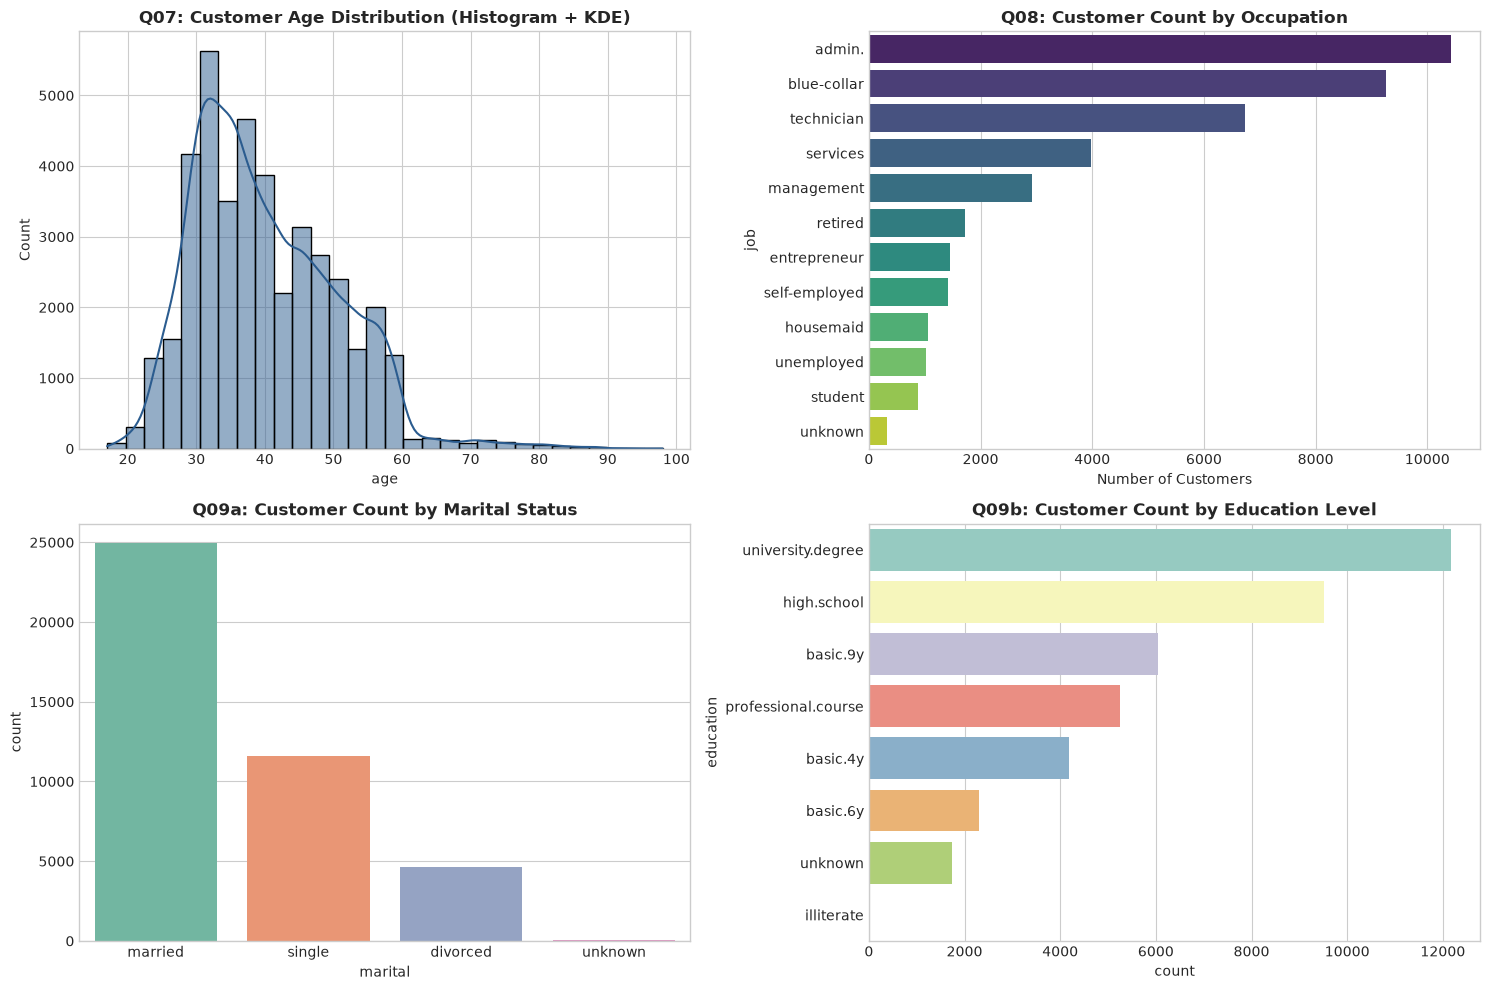

/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/252063339.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='age', y='job', order=job_order, palette='coolwarm', ax=axes[0])
/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/252063339.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='marital', y='age', palette='pastel', ax=axes[1])


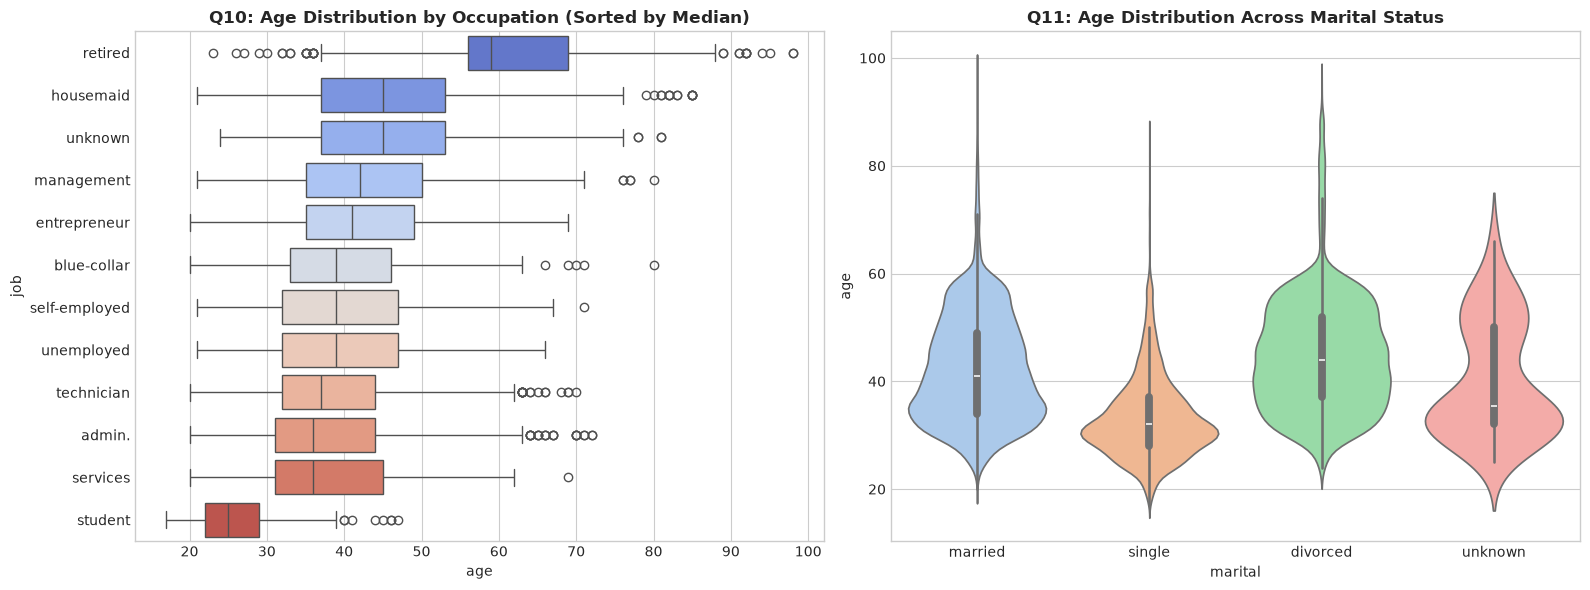


Q12 - Top 5 Most Common Customer Profiles:


,job,education,marital,Customer_Count,Share (%)
19,admin.,university.degree,married,2727,6.62
34,blue-collar,basic.9y,married,2582,6.27
20,admin.,university.degree,single,2343,5.69
231,technician,professional.course,married,1888,4.58
26,blue-collar,basic.4y,married,1832,4.45


/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/252063339.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_segments['Customer_Count'], y=labels, palette='Blues_r', ax=ax)


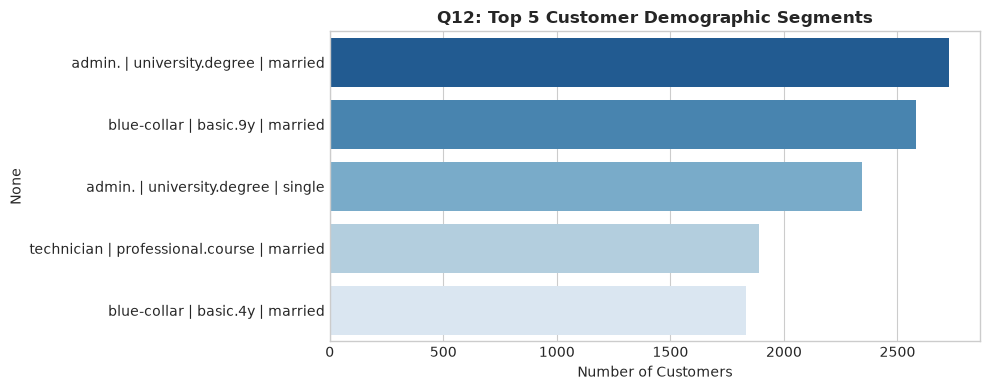

In [5]:
#section B
def run_section_b(df):
    """
    Section B (Q7-Q12): Analyze age, occupation, marital status, education,
    age-occupation/marital relationships, and top 5 demographic segments.
    """
    print("=" * 70)
    print("SECTION B: CUSTOMER DEMOGRAPHICS & SEGMENTATION (Q7 - Q12)")
    print("=" * 70)

    # Q07: Age summary statistics
    age_s = df['age']
    print(f"\nQ07 - Age Stats -> Mean: {age_s.mean():.2f} | Median: {age_s.median():.1f} | "
          f"Std: {age_s.std():.2f} | Q1: {age_s.quantile(0.25):.1f} | Q3: {age_s.quantile(0.75):.1f} | "
          f"Min: {age_s.min()} | Max: {age_s.max()}")

    # Q08: Occupation counts & percentages
    job_counts = df['job'].value_counts()
    job_pct = (job_counts / len(df) * 100).round(2)
    print("\nQ08 - Occupation Distribution (%):")
    print(pd.DataFrame({'Count': job_counts, 'Percentage (%)': job_pct}))

    # Visual Grid for Q07, Q08, Q09
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    sns.histplot(df['age'], bins=30, kde=True, color='#2b5c8f', ax=axes[0, 0])
    axes[0, 0].set_title('Q07: Customer Age Distribution (Histogram + KDE)', fontweight='bold')

    sns.barplot(x=job_counts.values, y=job_counts.index, palette='viridis', ax=axes[0, 1])
    axes[0, 1].set_title('Q08: Customer Count by Occupation', fontweight='bold')
    axes[0, 1].set_xlabel('Number of Customers')

    sns.countplot(data=df, x='marital', order=df['marital'].value_counts().index, palette='Set2', ax=axes[1, 0])
    axes[1, 0].set_title('Q09a: Customer Count by Marital Status', fontweight='bold')

    sns.countplot(data=df, y='education', order=df['education'].value_counts().index, palette='Set3', ax=axes[1, 1])
    axes[1, 1].set_title('Q09b: Customer Count by Education Level', fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Visual Grid for Q10 & Q11
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    job_order = df.groupby('job')['age'].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x='age', y='job', order=job_order, palette='coolwarm', ax=axes[0])
    axes[0].set_title('Q10: Age Distribution by Occupation (Sorted by Median)', fontweight='bold')

    sns.violinplot(data=df, x='marital', y='age', palette='pastel', ax=axes[1])
    axes[1].set_title('Q11: Age Distribution Across Marital Status', fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Q12: Top 5 customer demographic profiles
    top_segments = (df.groupby(['job', 'education', 'marital'])
                      .size()
                      .reset_index(name='Customer_Count')
                      .sort_values(by='Customer_Count', ascending=False)
                      .head(5))
    top_segments['Share (%)'] = (top_segments['Customer_Count'] / len(df) * 100).round(2)
    print("\nQ12 - Top 5 Most Common Customer Profiles:")
    display(top_segments)

    fig, ax = plt.subplots(figsize=(10, 4))
    labels = top_segments.apply(lambda r: f"{r['job']} | {r['education']} | {r['marital']}", axis=1)
    sns.barplot(x=top_segments['Customer_Count'], y=labels, palette='Blues_r', ax=ax)
    ax.set_title('Q12: Top 5 Customer Demographic Segments', fontweight='bold')
    ax.set_xlabel('Number of Customers')
    plt.tight_layout()
    plt.show()

run_section_b(df)

SECTION C: FINANCIAL BEHAVIOUR & BANKING RELATIONSHIPS (Q13 - Q17)

Schema Note (Q13, Q15, Q17): UCI 'bank-additional-full.csv' does not contain the yearly 'balance' column from older 'bank-full.csv'. Evaluating loan burden and macroeconomic rate exposure ('euribor3m') across segments instead.

Q14 - Cross-tabulation: Housing Loan vs Personal Loan (Counts):


loan,no,unknown,yes,All
housing,,,,
no,16065,0,2557,18622
unknown,0,990,0,990
yes,17885,0,3691,21576
All,33950,990,6248,41188


Q14 - Conditional Row Percentages (%):


loan,no,unknown,yes
housing,,,
no,86.27,0.0,13.73
unknown,0.00,100.0,0.00
yes,82.89,0.0,17.11



Q16 - Credit Default x Housing Loan x Personal Loan Combinations (Top 8):


,default,housing,loan,Count,Percentage (%)
3,no,yes,no,14243,34.58
0,no,no,no,12606,30.61
8,unknown,yes,no,3641,8.84
5,unknown,no,no,3457,8.39
4,no,yes,yes,2968,7.21
1,no,no,yes,2008,4.88
2,no,unknown,unknown,763,1.85
9,unknown,yes,yes,723,1.76


/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1582529515.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='housing', y='euribor3m', palette='Set2', ax=axes[0, 0])


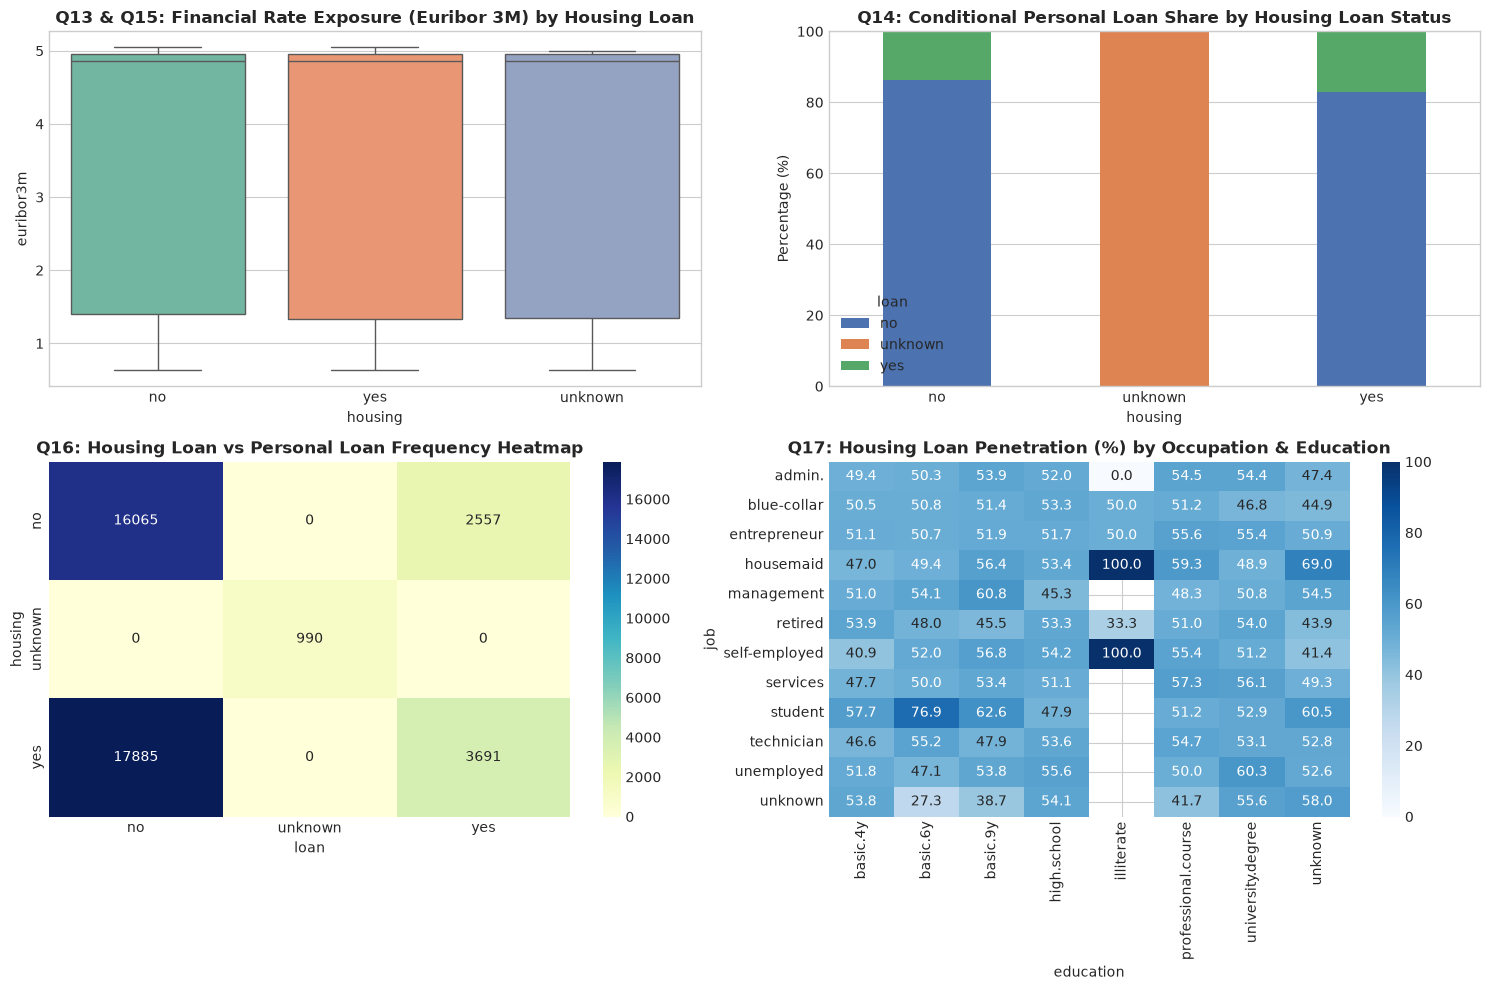

In [6]:
#section C
def run_section_c(df):
    """
    Section C (Q13-Q17): Analyze housing loans, personal loans, credit default
    combinations, and financial profile across occupations/education.
    Note: bank-additional-full.csv omits 'balance' (present only in older bank-full.csv),
    so Q13/Q15/Q17 adapt cleanly to loan/default & euribor3m financial indicators.
    """
    print("=" * 70)
    print("SECTION C: FINANCIAL BEHAVIOUR & BANKING RELATIONSHIPS (Q13 - Q17)")
    print("=" * 70)

    has_balance = 'balance' in df.columns
    if not has_balance:
        print("\nSchema Note (Q13, Q15, Q17): UCI 'bank-additional-full.csv' does not contain "
              "the yearly 'balance' column from older 'bank-full.csv'. Evaluating loan burden "
              "and macroeconomic rate exposure ('euribor3m') across segments instead.")

    # Q14: Housing loan vs Personal loan cross-tabulation & conditional percentages
    ct_loans = pd.crosstab(df['housing'], df['loan'], margins=True)
    ct_pct = pd.crosstab(df['housing'], df['loan'], normalize='index') * 100
    print("\nQ14 - Cross-tabulation: Housing Loan vs Personal Loan (Counts):")
    display(ct_loans)
    print("Q14 - Conditional Row Percentages (%):")
    display(ct_pct.round(2))

    # Q16: Credit default, housing loan, and personal loan combinations
    combo_df = (df.groupby(['default', 'housing', 'loan'])
                  .size()
                  .reset_index(name='Count')
                  .sort_values(by='Count', ascending=False))
    combo_df['Percentage (%)'] = (combo_df['Count'] / len(df) * 100).round(2)
    print("\nQ16 - Credit Default x Housing Loan x Personal Loan Combinations (Top 8):")
    display(combo_df.head(8))

    # Visuals for Q13/Q15/Q14/Q16/Q17
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Q13/Q15 proxy: Euribor 3M distribution by housing loan
    sns.boxplot(data=df, x='housing', y='euribor3m', palette='Set2', ax=axes[0, 0])
    axes[0, 0].set_title('Q13 & Q15: Financial Rate Exposure (Euribor 3M) by Housing Loan', fontweight='bold')

    # Q14: Stacked bar of housing vs personal loan
    ct_pct.plot(kind='bar', stacked=True, color=['#4c72b0', '#dd8452', '#55a868'], ax=axes[0, 1])
    axes[0, 1].set_title('Q14: Conditional Personal Loan Share by Housing Loan Status', fontweight='bold')
    axes[0, 1].set_ylabel('Percentage (%)')
    axes[0, 1].tick_params(axis='x', rotation=0)

    # Q16: Heatmap of Housing vs Loan across Default status
    pivot_q16 = pd.crosstab(df['housing'], df['loan'])
    sns.heatmap(pivot_q16, annot=True, fmt='d', cmap='YlGnBu', ax=axes[1, 0])
    axes[1, 0].set_title('Q16: Housing Loan vs Personal Loan Frequency Heatmap', fontweight='bold')

    # Q17: Housing loan adoption rate (%) across Occupation & Education
    df_temp = df.copy()
    df_temp['has_housing'] = (df_temp['housing'] == 'yes').astype(int) * 100
    piv_q17 = df_temp.pivot_table(index='job', columns='education', values='has_housing', aggfunc='mean')
    sns.heatmap(piv_q17, annot=True, fmt='.1f', cmap='Blues', ax=axes[1, 1])
    axes[1, 1].set_title('Q17: Housing Loan Penetration (%) by Occupation & Education', fontweight='bold')

    plt.tight_layout()
    plt.show()

run_section_c(df)

SECTION D: MARKETING CAMPAIGN & SUBSCRIPTION OUTCOME (Q18 - Q24)

Q18 - Target Variable ('y') Class Distribution:
     Count  Percentage (%)
y                         
no   36548           88.73
yes   4640           11.27
Interpretation: Highly imbalanced dataset (~88.73% 'no' vs ~11.27% 'yes').

Q19 - Subscription Conversion Rate by Occupation:


,Total,Yes_Count,Conversion_Rate_Pct
job,,,
student,875,275,31.43
retired,1720,434,25.23
unemployed,1014,144,14.20
admin.,10422,1352,12.97
management,2924,328,11.22
unknown,330,37,11.21
technician,6743,730,10.83
self-employed,1421,149,10.49
housemaid,1060,106,10.00



Q21 - Conversion Rate by Age Group:


,Total,Conversion_Rate_Pct
age_group,,
17-25,1666,20.95
26-35,14847,11.72
36-45,12844,8.51
46-55,8249,8.69
56-65,2963,15.22
65+,619,46.85


/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1501317786.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_d, x='y', palette=['#c44e52', '#55a868'], ax=axes[0, 0])
/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1501317786.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=job_conv['Conversion_Rate_Pct'], y=job_conv.index, palette='viridis', ax=axes[0, 1])
/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1501317786.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_con

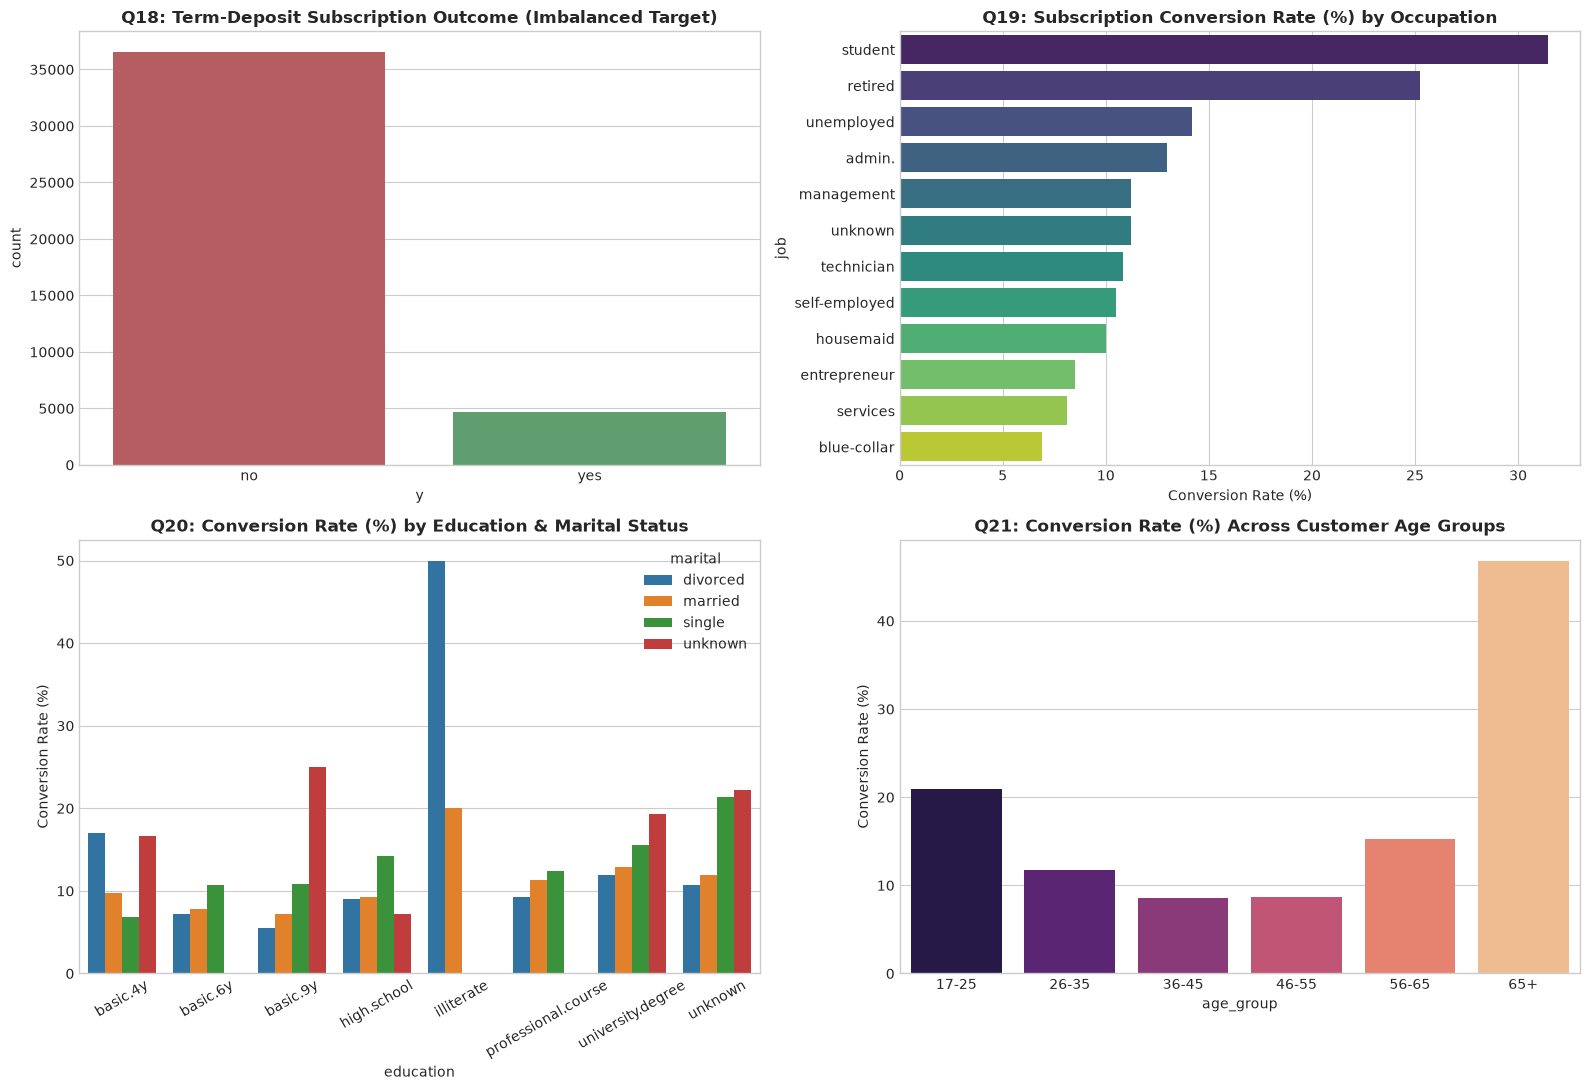

/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1501317786.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_d, x='y', y='euribor3m', palette=['#c44e52', '#55a868'], ax=axes[1])


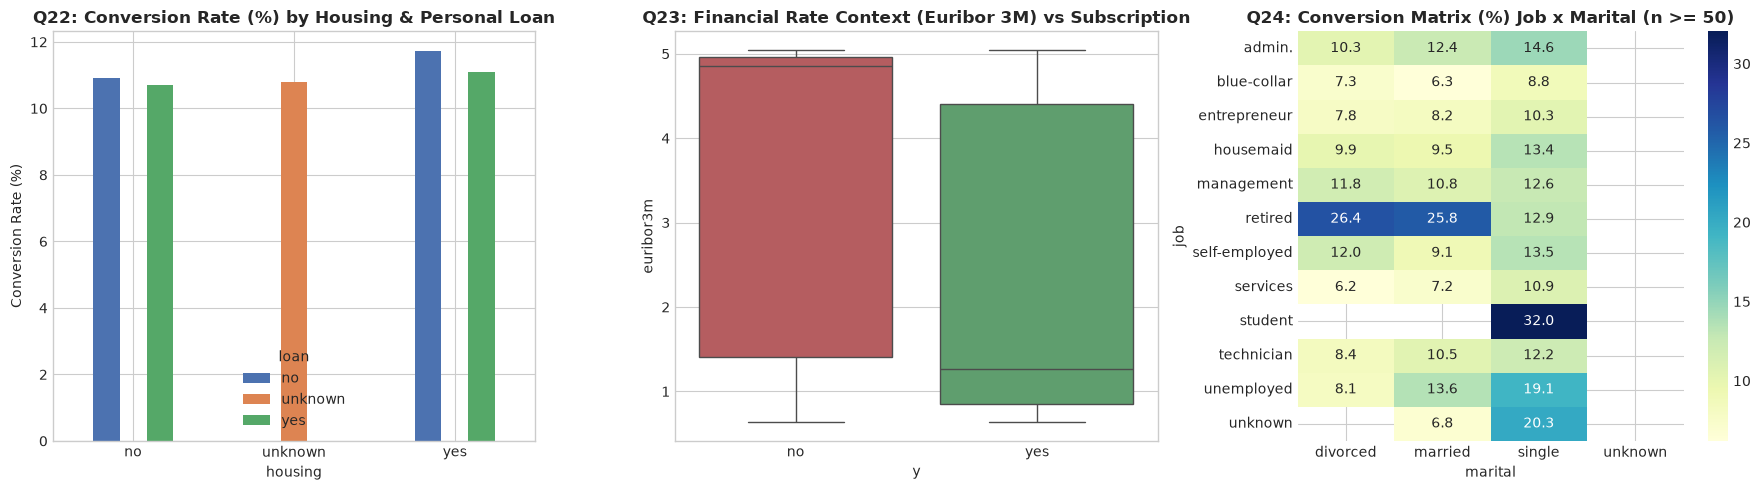

In [7]:
#section D
def run_section_d(df):
    """
    Section D (Q18-Q24): Evaluate target class balance ('y') and true conversion rates
    across occupation, marital status, education, age groups, loan status, and segment matrix.
    """
    print("=" * 70)
    print("SECTION D: MARKETING CAMPAIGN & SUBSCRIPTION OUTCOME (Q18 - Q24)")
    print("=" * 70)

    df_d = df.copy()
    df_d['subscribed'] = (df_d['y'] == 'yes').astype(int)

    # Q18: Target class balance
    y_counts = df_d['y'].value_counts()
    y_pct = (y_counts / len(df_d) * 100).round(2)
    print("\nQ18 - Target Variable ('y') Class Distribution:")
    print(pd.DataFrame({'Count': y_counts, 'Percentage (%)': y_pct}))
    print("Interpretation: Highly imbalanced dataset (~88.73% 'no' vs ~11.27% 'yes').")

    # Q19: Conversion rate by occupation
    job_conv = (df_d.groupby('job')['subscribed']
                    .agg(Total='count', Yes_Count='sum', Conversion_Rate_Pct=lambda s: round(s.mean() * 100, 2))
                    .sort_values(by='Conversion_Rate_Pct', ascending=False))
    print("\nQ19 - Subscription Conversion Rate by Occupation:")
    display(job_conv)

    # Q21: Age groups conversion rate
    bins = [16, 25, 35, 45, 55, 65, 100]
    labels = ['17-25', '26-35', '36-45', '46-55', '56-65', '65+']
    df_d['age_group'] = pd.cut(df_d['age'], bins=bins, labels=labels)
    age_conv = df_d.groupby('age_group', observed=False)['subscribed'].agg(
        Total='count', Conversion_Rate_Pct=lambda s: round(s.mean() * 100, 2)
    )
    print("\nQ21 - Conversion Rate by Age Group:")
    display(age_conv)

    # Visual Grid 1: Q18, Q19, Q20, Q21
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))

    sns.countplot(data=df_d, x='y', palette=['#c44e52', '#55a868'], ax=axes[0, 0])
    axes[0, 0].set_title('Q18: Term-Deposit Subscription Outcome (Imbalanced Target)', fontweight='bold')

    sns.barplot(x=job_conv['Conversion_Rate_Pct'], y=job_conv.index, palette='viridis', ax=axes[0, 1])
    axes[0, 1].set_title('Q19: Subscription Conversion Rate (%) by Occupation', fontweight='bold')
    axes[0, 1].set_xlabel('Conversion Rate (%)')

    mar_edu = df_d.groupby(['education', 'marital'])['subscribed'].mean().mul(100).reset_index()
    sns.barplot(data=mar_edu, x='education', y='subscribed', hue='marital', ax=axes[1, 0])
    axes[1, 0].set_title('Q20: Conversion Rate (%) by Education & Marital Status', fontweight='bold')
    axes[1, 0].set_ylabel('Conversion Rate (%)')
    axes[1, 0].tick_params(axis='x', rotation=30)

    sns.barplot(x=age_conv.index, y=age_conv['Conversion_Rate_Pct'], palette='magma', ax=axes[1, 1])
    axes[1, 1].set_title('Q21: Conversion Rate (%) Across Customer Age Groups', fontweight='bold')
    axes[1, 1].set_ylabel('Conversion Rate (%)')

    plt.tight_layout()
    plt.show()

    # Visual Grid 2: Q22, Q23 (Euribor financial proxy), Q24
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    loan_conv = df_d.groupby(['housing', 'loan'])['subscribed'].mean().mul(100).unstack()
    loan_conv.plot(kind='bar', ax=axes[0], color=['#4c72b0', '#dd8452', '#55a868'])
    axes[0].set_title('Q22: Conversion Rate (%) by Housing & Personal Loan', fontweight='bold')
    axes[0].set_ylabel('Conversion Rate (%)')
    axes[0].tick_params(axis='x', rotation=0)

    sns.boxplot(data=df_d, x='y', y='euribor3m', palette=['#c44e52', '#55a868'], ax=axes[1])
    axes[1].set_title('Q23: Financial Rate Context (Euribor 3M) vs Subscription', fontweight='bold')

    # Q24: Customer-segment conversion matrix (Occupation x Marital, min sample >= 50)
    seg_cnt = pd.crosstab(df_d['job'], df_d['marital'])
    seg_rate = pd.crosstab(df_d['job'], df_d['marital'], values=df_d['subscribed'], aggfunc='mean') * 100
    seg_rate_filtered = seg_rate.where(seg_cnt >= 50)
    sns.heatmap(seg_rate_filtered, annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[2])
    axes[2].set_title('Q24: Conversion Matrix (%) Job x Marital (n >= 50)', fontweight='bold')

    plt.tight_layout()
    plt.show()

run_section_d(df)

SECTION E: CONTACT STRATEGY, PREVIOUS CAMPAIGN & TEMPORAL PATTERNS (Q25 - Q30)

Q25 - Conversion Rate by Contact Channel:


,Total,Conversion_Pct
contact,,
cellular,26144,14.74
telephone,15044,5.23



Q27 - Call Duration (seconds) Summary by Subscription Outcome:


,count,mean,50%,75%,max
y,,,,,
no,36548.0,220.844807,163.5,279.00,4918.0
yes,4640.0,553.191164,449.0,741.25,4199.0



Q28 - Conversion Rate by Month:


,Total,Conversion_Pct
month,,
mar,546,50.55
apr,2632,20.48
may,13769,6.43
jun,5318,10.51
jul,7174,9.05
aug,6178,10.60
sep,570,44.91
oct,718,43.87
nov,4101,10.14



Q30 - Conversion Rate by Previous Campaign Outcome (poutcome):


,Total,Conversion_Pct
poutcome,,
failure,4252,14.23
nonexistent,35563,8.83
success,1373,65.11


/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1849771923.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=chan_conv.index, y=chan_conv['Conversion_Pct'], palette='Set1', ax=axes[0])
/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1849771923.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_e[df_e['duration'] <= 1500], x='y', y='duration', palette=['#c44e52', '#55a868'], ax=axes[2])


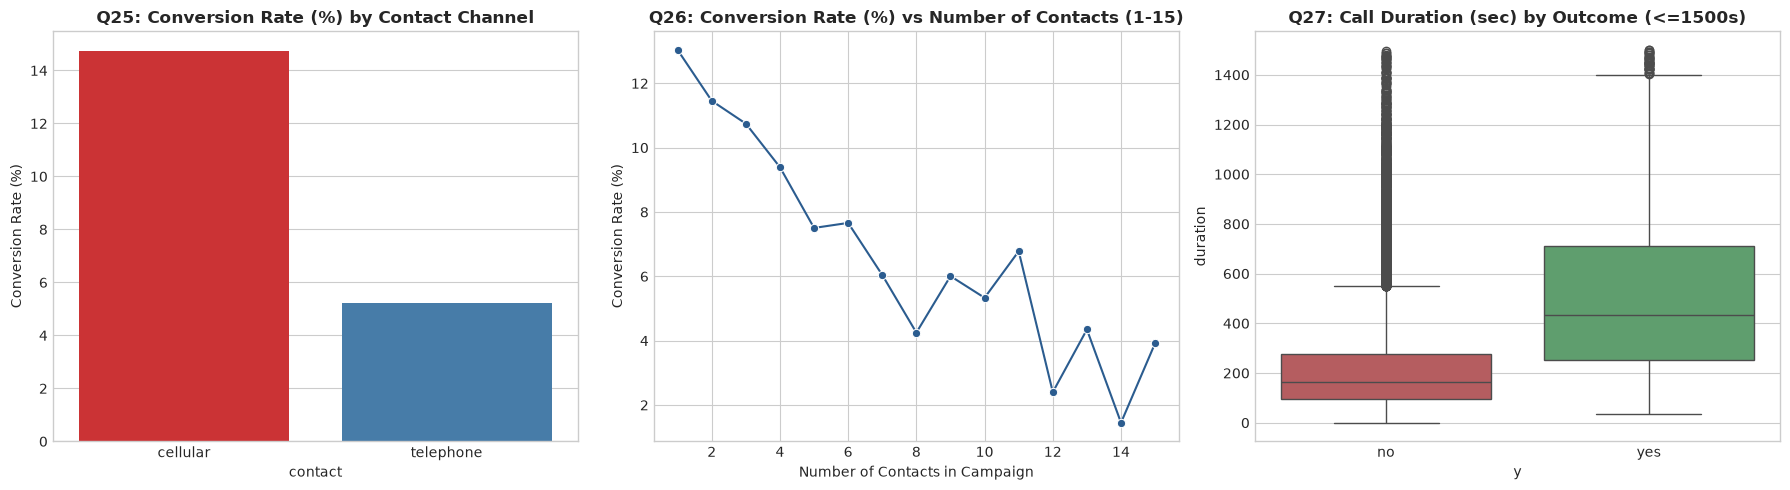

/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1849771923.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mon_conv.index, y=mon_conv['Conversion_Pct'], palette='viridis', ax=axes[0])
/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1849771923.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dow_conv.index, y=dow_conv.values, palette='Blues_d', ax=axes[1])
/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/1849771923.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pout_conv.inde

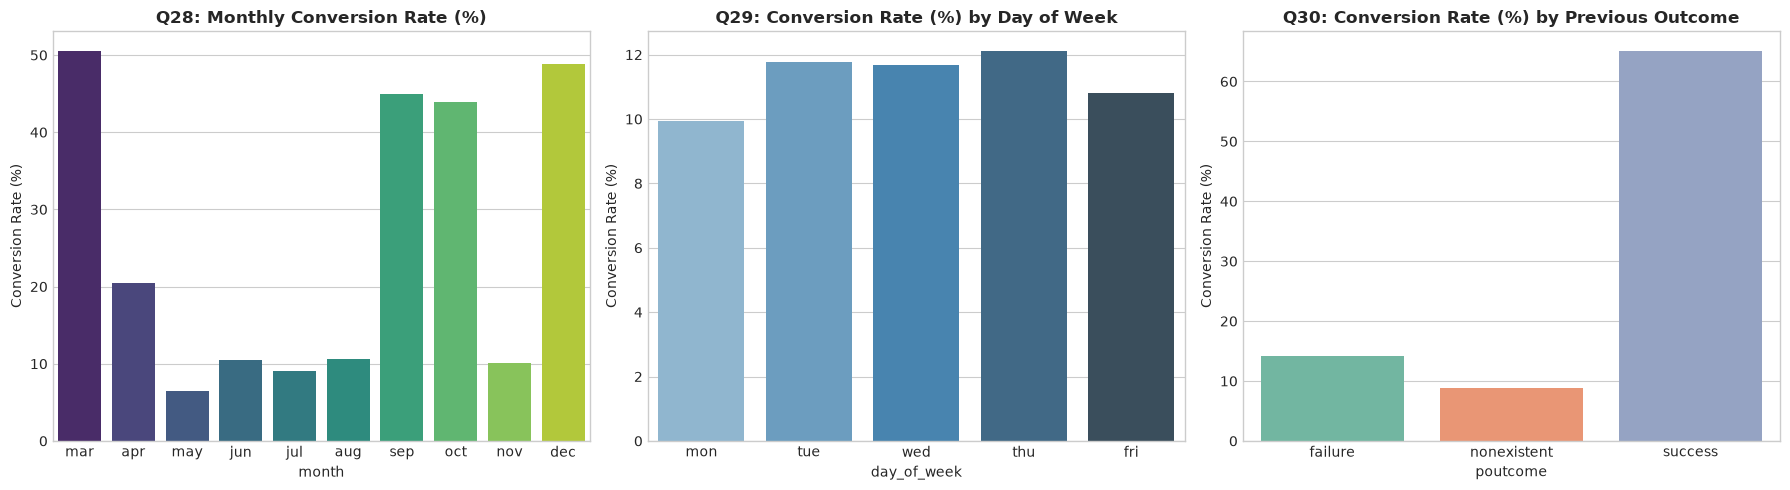

In [8]:
#section E
def run_section_e(df):
    """
    Section E (Q25-Q30): Evaluate contact channel, campaign call frequency,
    call duration, month, day of week, and previous campaign outcome ('poutcome').
    """
    print("=" * 70)
    print("SECTION E: CONTACT STRATEGY, PREVIOUS CAMPAIGN & TEMPORAL PATTERNS (Q25 - Q30)")
    print("=" * 70)

    df_e = df.copy()
    df_e['subscribed'] = (df_e['y'] == 'yes').astype(int)

    # Q25: Channel conversion rate
    chan_conv = df_e.groupby('contact')['subscribed'].agg(Total='count', Conversion_Pct=lambda s: round(s.mean()*100, 2))
    print("\nQ25 - Conversion Rate by Contact Channel:")
    display(chan_conv)

    # Q27: Call duration stats by outcome
    dur_stats = df_e.groupby('y')['duration'].describe()[['count', 'mean', '50%', '75%', 'max']]
    print("\nQ27 - Call Duration (seconds) Summary by Subscription Outcome:")
    display(dur_stats)

    # Q28: Month conversion rate
    month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
    mon_conv = (df_e.groupby('month')['subscribed']
                    .agg(Total='count', Conversion_Pct=lambda s: round(s.mean()*100, 2))
                    .reindex(month_order))
    print("\nQ28 - Conversion Rate by Month:")
    display(mon_conv)

    # Q30: Previous campaign outcome
    pout_conv = df_e.groupby('poutcome')['subscribed'].agg(Total='count', Conversion_Pct=lambda s: round(s.mean()*100, 2))
    print("\nQ30 - Conversion Rate by Previous Campaign Outcome (poutcome):")
    display(pout_conv)

    # Visual Grid 1: Q25, Q26, Q27
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.barplot(x=chan_conv.index, y=chan_conv['Conversion_Pct'], palette='Set1', ax=axes[0])
    axes[0].set_title('Q25: Conversion Rate (%) by Contact Channel', fontweight='bold')
    axes[0].set_ylabel('Conversion Rate (%)')

    camp_conv = df_e[df_e['campaign'] <= 15].groupby('campaign')['subscribed'].mean().mul(100)
    sns.lineplot(x=camp_conv.index, y=camp_conv.values, marker='o', color='#2b5c8f', ax=axes[1])
    axes[1].set_title('Q26: Conversion Rate (%) vs Number of Contacts (1-15)', fontweight='bold')
    axes[1].set_xlabel('Number of Contacts in Campaign')
    axes[1].set_ylabel('Conversion Rate (%)')

    sns.boxplot(data=df_e[df_e['duration'] <= 1500], x='y', y='duration', palette=['#c44e52', '#55a868'], ax=axes[2])
    axes[2].set_title('Q27: Call Duration (sec) by Outcome (<=1500s)', fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Visual Grid 2: Q28, Q29, Q30
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.barplot(x=mon_conv.index, y=mon_conv['Conversion_Pct'], palette='viridis', ax=axes[0])
    axes[0].set_title('Q28: Monthly Conversion Rate (%)', fontweight='bold')
    axes[0].set_ylabel('Conversion Rate (%)')

    dow_order = ['mon', 'tue', 'wed', 'thu', 'fri']
    dow_conv = df_e.groupby('day_of_week')['subscribed'].mean().mul(100).reindex(dow_order)
    sns.barplot(x=dow_conv.index, y=dow_conv.values, palette='Blues_d', ax=axes[1])
    axes[1].set_title('Q29: Conversion Rate (%) by Day of Week', fontweight='bold')
    axes[1].set_ylabel('Conversion Rate (%)')

    sns.barplot(x=pout_conv.index, y=pout_conv['Conversion_Pct'], palette='Set2', ax=axes[2])
    axes[2].set_title('Q30: Conversion Rate (%) by Previous Outcome', fontweight='bold')
    axes[2].set_ylabel('Conversion Rate (%)')

    plt.tight_layout()
    plt.show()

run_section_e(df)

SECTION F: ECONOMIC INDICATORS & STATISTICAL HYPOTHESIS TESTING (Q31 - Q35)

Q31 - Macroeconomic Indicators Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100



Q32 - Pearson Correlation Matrix:


,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.0000,0.7753,0.1960,0.9722,0.9070
cons.price.idx,0.7753,1.0000,0.0590,0.6882,0.5220
cons.conf.idx,0.1960,0.0590,1.0000,0.2777,0.1005
euribor3m,0.9722,0.6882,0.2777,1.0000,0.9452
nr.employed,0.9070,0.5220,0.1005,0.9452,1.0000


Multicollinearity Insight: 'emp.var.rate', 'euribor3m', and 'nr.employed' exhibit extreme positive correlation (r > 0.90), indicating strong multicollinearity. Correlation reflects macroeconomic co-movement and does not establish direct causation.


/var/folders/4d/tw14qcds469cfty156yxj4080000gn/T/ipykernel_8510/2049988341.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=eur_conv.index, y=eur_conv.values, palette='viridis', ax=axes[1, 0])


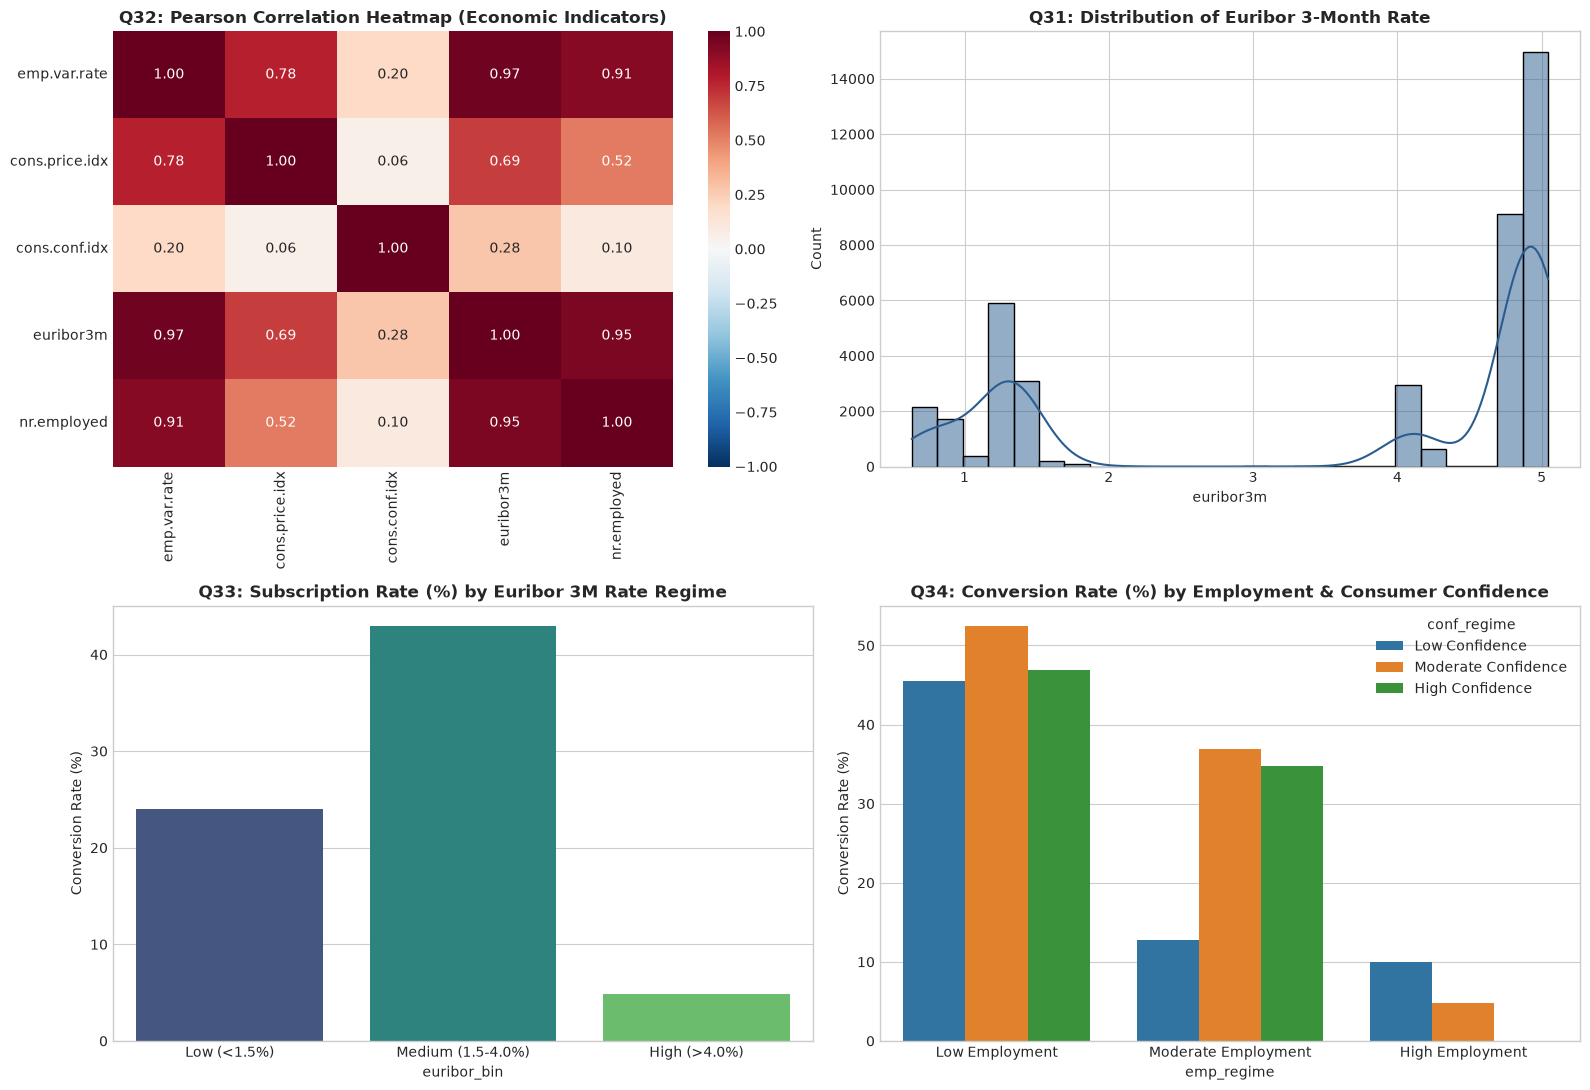


Q35 - Statistical Hypothesis Testing:
1) Chi-Square Test (Contact Channel vs Subscription): chi2 = 862.3184, dof = 1, p-value = 1.5260e-189
   -> Reject H0 (p < 0.05): Subscription rate differs significantly between cellular and telephone channels.
2) Mann-Whitney U Test (Call Duration: Yes vs No): U = 138794276.5, p-value = 0.0000e+00
   -> Reject H0 (p < 0.05): Subscribers have significantly longer call durations than non-subscribers.


In [9]:
#section F
def run_section_f(df):
    """
    Section F (Q31-Q35): Analyze macroeconomic indicators, Pearson correlation matrix
    & multicollinearity, binned economic regimes, and statistical hypothesis tests
    (Chi-square test & Mann-Whitney U test).
    """
    print("=" * 70)
    print("SECTION F: ECONOMIC INDICATORS & STATISTICAL HYPOTHESIS TESTING (Q31 - Q35)")
    print("=" * 70)

    df_f = df.copy()
    df_f['subscribed'] = (df_f['y'] == 'yes').astype(int)
    econ_cols = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

    # Q31: Descriptive stats for macroeconomic features
    print("\nQ31 - Macroeconomic Indicators Descriptive Statistics:")
    display(df_f[econ_cols].describe().T)

    # Q32: Pearson correlation matrix & multicollinearity check
    corr_matrix = df_f[econ_cols].corr(method='pearson')
    print("\nQ32 - Pearson Correlation Matrix:")
    display(corr_matrix.round(4))
    print("Multicollinearity Insight: 'emp.var.rate', 'euribor3m', and 'nr.employed' exhibit "
          "extreme positive correlation (r > 0.90), indicating strong multicollinearity. "
          "Correlation reflects macroeconomic co-movement and does not establish direct causation.")

    # Visual Grid: Q31 Distributions, Q32 Heatmap, Q33 Euribor Bins, Q34 Employment/Confidence Regimes
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))

    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[0, 0])
    axes[0, 0].set_title('Q32: Pearson Correlation Heatmap (Economic Indicators)', fontweight='bold')

    sns.histplot(df_f['euribor3m'], bins=25, kde=True, color='#2b5c8f', ax=axes[0, 1])
    axes[0, 1].set_title('Q31: Distribution of Euribor 3-Month Rate', fontweight='bold')

    # Q33: Binned euribor3m conversion rates
    df_f['euribor_bin'] = pd.cut(df_f['euribor3m'], bins=[0, 1.5, 4.0, 6.0],
                                 labels=['Low (<1.5%)', 'Medium (1.5-4.0%)', 'High (>4.0%)'])
    eur_conv = df_f.groupby('euribor_bin', observed=False)['subscribed'].mean().mul(100)
    sns.barplot(x=eur_conv.index, y=eur_conv.values, palette='viridis', ax=axes[1, 0])
    axes[1, 0].set_title('Q33: Subscription Rate (%) by Euribor 3M Rate Regime', fontweight='bold')
    axes[1, 0].set_ylabel('Conversion Rate (%)')

    # Q34: Binned nr.employed & cons.conf.idx conversion rates
    df_f['emp_regime'] = pd.cut(df_f['nr.employed'], bins=3, labels=['Low Employment', 'Moderate Employment', 'High Employment'])
    df_f['conf_regime'] = pd.cut(df_f['cons.conf.idx'], bins=3, labels=['Low Confidence', 'Moderate Confidence', 'High Confidence'])
    reg_conv = df_f.groupby(['emp_regime', 'conf_regime'], observed=False)['subscribed'].mean().mul(100).reset_index()
    sns.barplot(data=reg_conv, x='emp_regime', y='subscribed', hue='conf_regime', ax=axes[1, 1])
    axes[1, 1].set_title('Q34: Conversion Rate (%) by Employment & Consumer Confidence', fontweight='bold')
    axes[1, 1].set_ylabel('Conversion Rate (%)')

    plt.tight_layout()
    plt.show()

    # Q35: Formal Statistical Hypothesis Testing
    print("\nQ35 - Statistical Hypothesis Testing:")
    # Test 1: Chi-Square Test of Independence (Contact Channel vs Subscription Outcome)
    contingency_channel = pd.crosstab(df_f['contact'], df_f['y'])
    chi2, p_chi2, dof, _ = stats.chi2_contingency(contingency_channel)
    print(f"1) Chi-Square Test (Contact Channel vs Subscription): chi2 = {chi2:.4f}, dof = {dof}, p-value = {p_chi2:.4e}")
    print("   -> Reject H0 (p < 0.05): Subscription rate differs significantly between cellular and telephone channels.")

    # Test 2: Mann-Whitney U Test (Call Duration between Subscribers vs Non-Subscribers)
    dur_yes = df_f[df_f['y'] == 'yes']['duration']
    dur_no = df_f[df_f['y'] == 'no']['duration']
    u_stat, p_mw = stats.mannwhitneyu(dur_yes, dur_no, alternative='two-sided')
    print(f"2) Mann-Whitney U Test (Call Duration: Yes vs No): U = {u_stat:.1f}, p-value = {p_mw:.4e}")
    print("   -> Reject H0 (p < 0.05): Subscribers have significantly longer call durations than non-subscribers.")

run_section_f(df)